## Plots of the model

In [8]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from model import Config
from behaviours import run_scenario, RULES
from metrics import summarize
from main import run_all

In [ ]:
# baseline scenario
cfg = Config(seed=42,scenario="COMBINED")
hist, park = run_scenario(cfg,42)

In [ ]:
results = run_all(Config(n_replications=50,seed=42))
pd.DataFrame(results)

,mean_utilization,max_utilization,congestion_share,realized_expansion,unrealized_expansion,queue_length,cooperation_count,demand_expansions,solar_expansions,scenario
0,0.901340,0.959180,0.0013,560.88,18.98,7.22,0.00,76.68,59.30,BASELINE
1,0.901279,0.957176,0.0012,563.36,18.28,8.38,0.00,73.98,61.48,HOMOPHILY
2,0.870212,0.897934,0.0010,571.02,4.90,1.48,289.14,49.52,86.80,NEIGHBOURS
3,0.858051,0.871710,0.0006,572.12,1.96,0.36,281.64,36.70,99.40,COMBINED


: 

In [23]:
def run_replications(cfg, scenario):
    rows = []
    for r in range(cfg.n_replications):
        seed = (cfg.seed or 0) + r
        cfg.scenario = scenario
        hist, park = run_scenario(cfg,seed,)

        rows.append(summarize(hist,park,))

    return pd.DataFrame(rows)

## Figure 1: compare scenarios

In [11]:
rows = []

cfg = Config(
    n_replications=20,
    seed=42
)
for scenario in RULES:
    df = run_replications(
        cfg,
        scenario
    )
    rows.append({
        "scenario": scenario,
        "congestion":
            df["congestion_share"].mean(),
        "utilization":
            df["mean_utilization"].mean(),
    })

results = pd.DataFrame(rows)
results

,scenario,congestion,utilization
0,BASELINE,0.00325,0.904806
1,HOMOPHILY,0.00300,0.904210
2,NEIGHBOURS,0.00250,0.875683
3,COMBINED,0.00150,0.864784


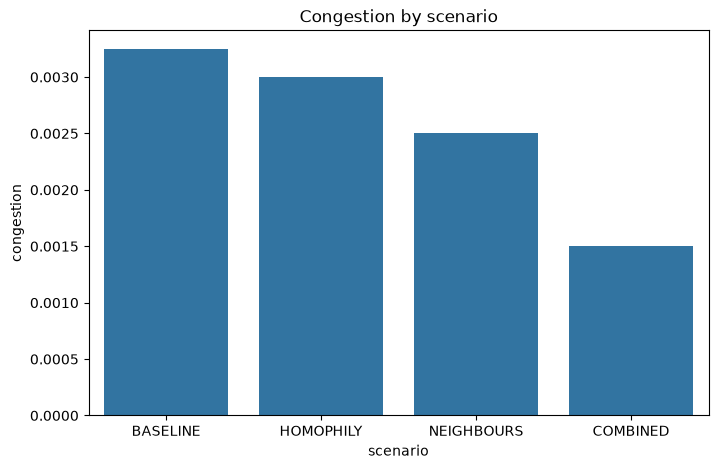

In [12]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="scenario",
    y="congestion"
)

plt.title(
    "Congestion by scenario"
)

plt.show()

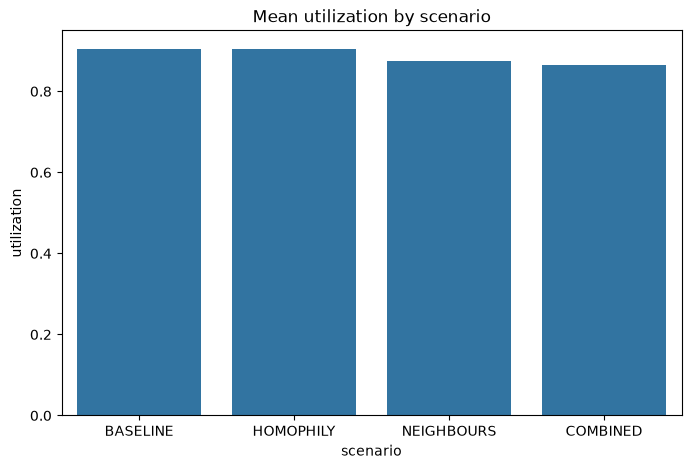

In [13]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="scenario",
    y="utilization"
)

plt.title("Mean utilization by scenario")

plt.show()

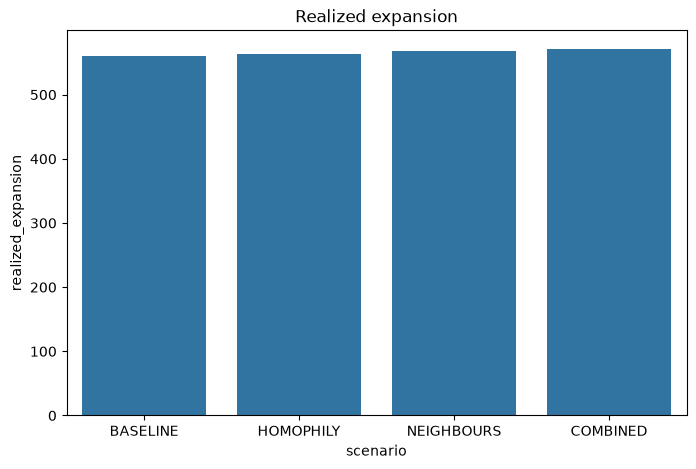

In [14]:
results = run_all(
    Config(
        grid_capacity=30000,
        coordination=0.25,
        coordination_influence=0.75,
        n_replications=50,
        seed=42,
    )
)

results = pd.DataFrame(results)

plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="scenario",
    y="realized_expansion"
)

plt.title("Realized expansion")

plt.show()


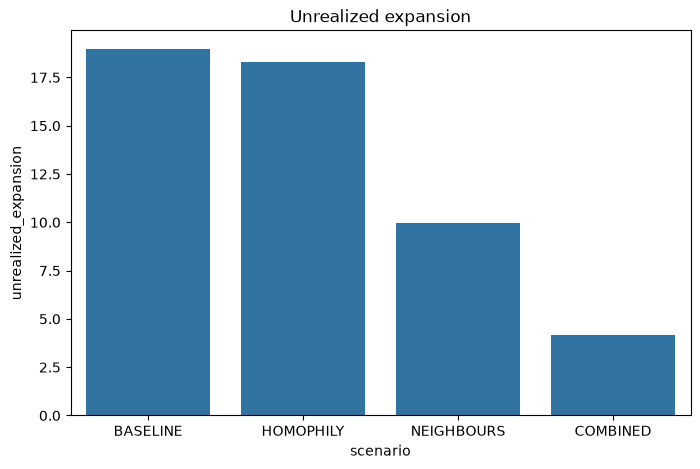

In [15]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="scenario",
    y="unrealized_expansion"
)

plt.title("Unrealized expansion")

plt.show()


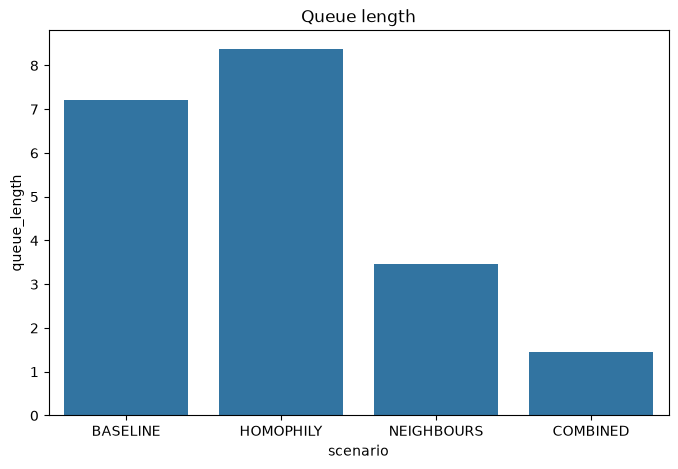

In [16]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="scenario",
    y="queue_length"
)

plt.title("Queue length")

plt.show()

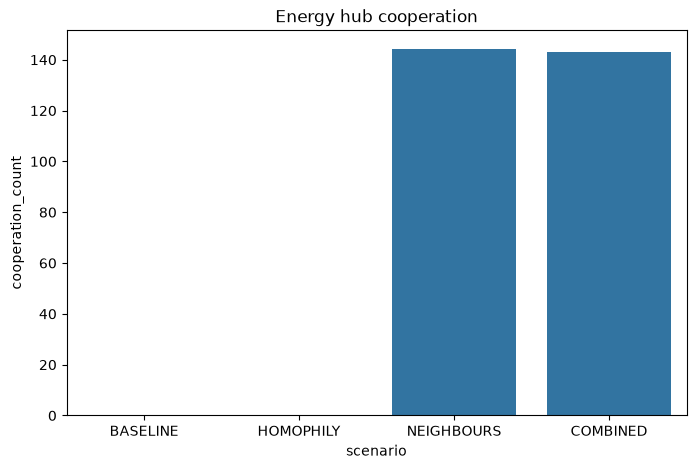

In [17]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results,
    x="scenario",
    y="cooperation_count"
)

plt.title("Energy hub cooperation")

plt.show()

## Figure 2: time series

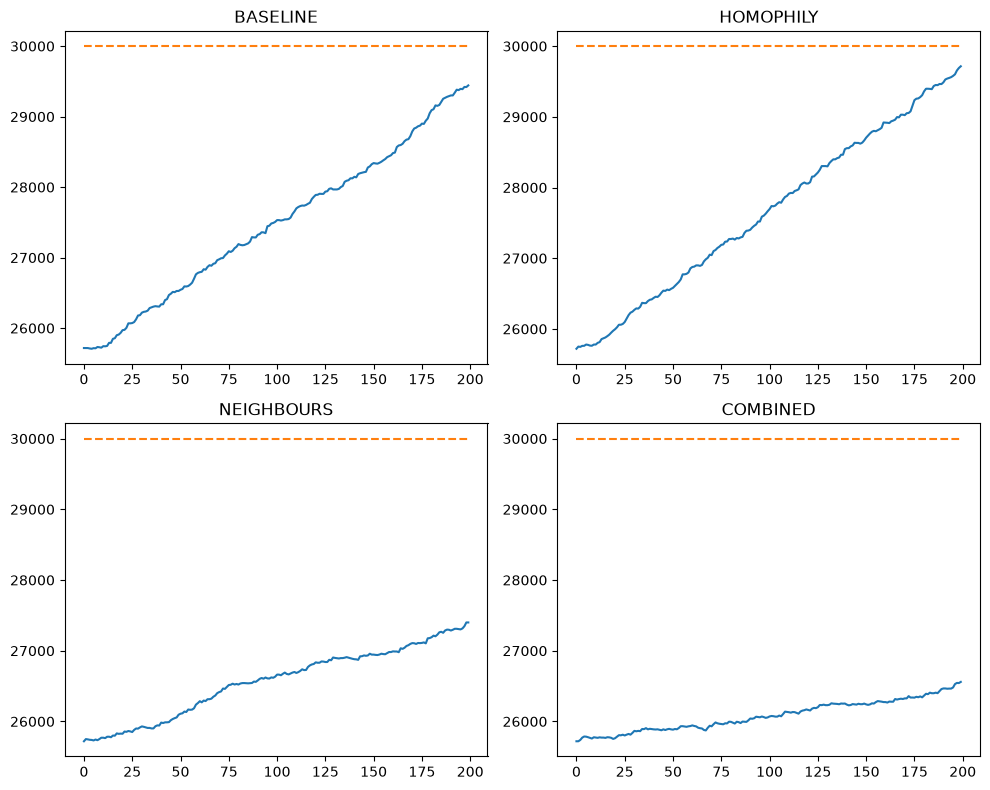

In [18]:
cfg = Config(seed=42)

fig, axes = plt.subplots(2,2,figsize=(10,8))
axes = axes.flatten()

for ax, scenario in zip(axes,RULES.keys()):
    cfg.scenario = scenario
    hist, park = run_scenario(cfg,42)

    ax.plot(
        [h["t"] for h in hist],
        [h["net_load"] for h in hist],
        label="net load"
    )

    ax.plot(
        [h["t"] for h in hist],
        [h["capacity"] for h in hist],
        "--",
        label="capacity"
    )

    ax.set_title(scenario)

plt.tight_layout()
plt.show()

## Figure 3: spatial heatmap

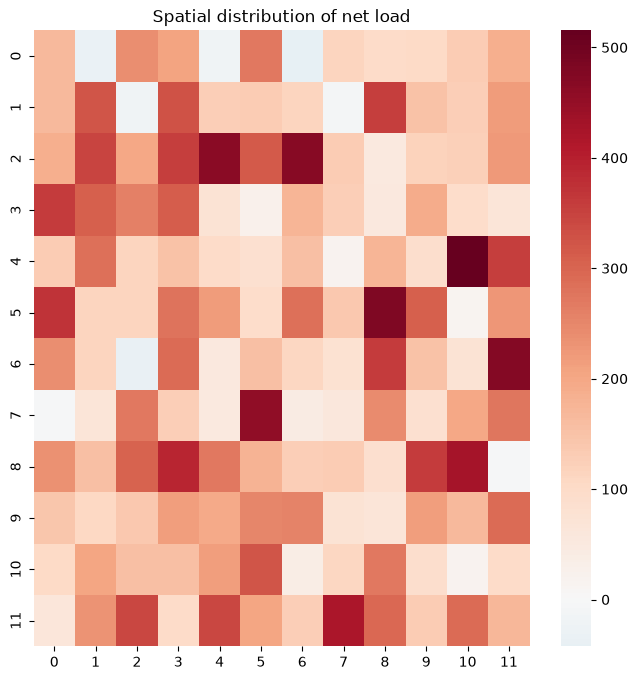

In [19]:
cfg = Config(seed=42,scenario="COMBINED")

hist, park = run_scenario(cfg,42)

plt.figure(figsize=(8,8))

sns.heatmap(
    park.load_grid(),
    cmap="RdBu_r",
    center=0
)

plt.title("Spatial distribution of net load")

plt.show()

## Figure 4: queue length phase diagram

100%|██████████| 11/11 [00:30<00:00,  2.75s/it]


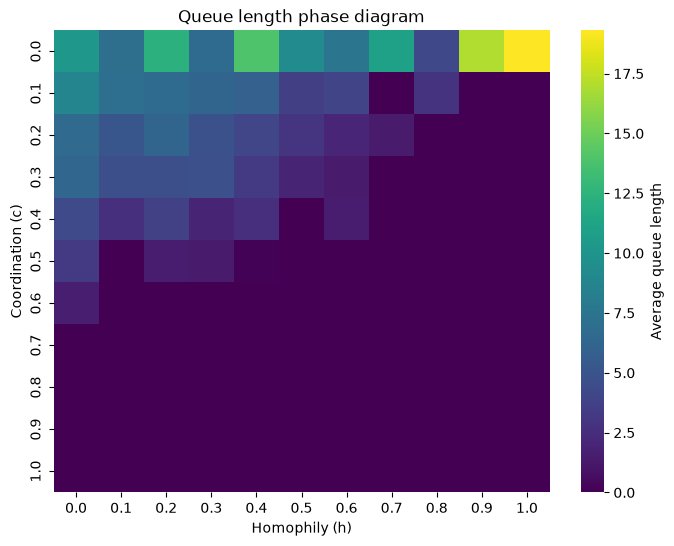

In [20]:
hs = np.arange(0, 1.05, 0.1)
cs = np.arange(0, 1.05, 0.1)

runs_per_cell = 10
heat = np.zeros((len(cs),len(hs)))

for i, c in enumerate(tqdm(cs)):
    for j, h in enumerate(hs):
        values = []
        for r in range(runs_per_cell):
            cfg = Config(
                scenario="COMBINED",
                homophily=h,
                coordination=c,
                coordination_influence=0.75,
                grid_capacity=30000,
                seed=r,
            )

            hist, park = run_scenario(cfg,r,)
            values.append(summarize(hist,park,)["queue_length"])

        heat[i, j] = np.mean(values)
plt.figure(figsize=(8,6))
sns.heatmap(
    heat,
    xticklabels=np.round(hs, 2),
    yticklabels=np.round(cs, 2),
    cmap="viridis",
    cbar_kws={
        "label": "Average queue length"
    }
)

plt.xlabel("Homophily (h)")
plt.ylabel("Coordination (c)")

plt.title("Queue length phase diagram")

plt.show()

## Figure 5: unrealized expansion phase diagram

100%|██████████| 11/11 [00:28<00:00,  2.61s/it]


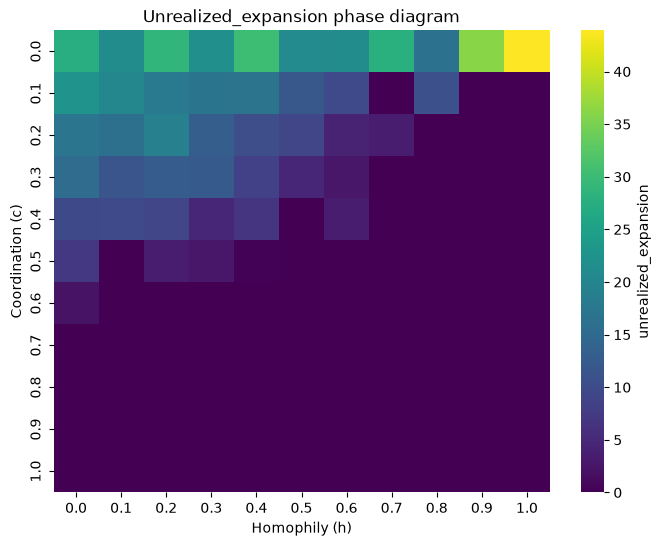

In [21]:
hs = np.arange(0, 1.05, 0.1)
cs = np.arange(0, 1.05, 0.1)

runs_per_cell = 10
heat = np.zeros((len(cs),len(hs)))

for i, c in enumerate(tqdm(cs)):
    for j, h in enumerate(hs):
        values = []
        for r in range(runs_per_cell):
            cfg = Config(
                scenario="COMBINED",
                homophily=h,
                coordination=c,
                coordination_influence=0.75,
                grid_capacity=30000,
                seed=r,
            )

            hist, park = run_scenario(cfg,r,)
            values.append(summarize(hist,park,)["unrealized_expansion"])

        heat[i, j] = np.mean(values)
plt.figure(figsize=(8,6))
sns.heatmap(
    heat,
    xticklabels=np.round(hs, 2),
    yticklabels=np.round(cs, 2),
    cmap="viridis",
    cbar_kws={
        "label": "unrealized_expansion"
    }
)

plt.xlabel("Homophily (h)")
plt.ylabel("Coordination (c)")

plt.title("Unrealized_expansion phase diagram")

plt.show()